# Experiment 2: compare approaches
Read completed portable summaries only, without simulator dependencies or raw transitions. Protocols, units, histogram bins, and per-profile seed coverage must match. Native method-specific PD gains are allowed. Missing results are unavailable, never zero.


In [1]:
import json, os, sys
from pathlib import Path
import pandas as pd
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "notebooks/exp2_analysis.py").exists())
sys.path.insert(0, str(ROOT / "notebooks"))
import exp2_analysis as analysis


## Configuration
Select one loading status at a time. All discovered methods enter the main table; focused tables/curves default to PILOT, UniFP, Pos. `trial_sd` bands show equal-seed mixture standard deviation across surviving trials, not SEM. `seed_sd` instead shows sample SD across seed means. Tables always use sample SD across evaluation seeds.


In [2]:
CONFIG = {
    "summary_roots": [str(ROOT / "analysis/exp2")],
    "output_dir": str(ROOT / "analysis/exp2_comparison"),
    "loading": "loaded",
    "method_order": ["b1z1_pact", "b1z1_unifp_original", "b1z1_ppo_pos"],
    "focused_methods": ["b1z1_pact", "b1z1_unifp_original", "b1z1_ppo_pos"],
    "display_names": {"b1z1_pact": "PILOT", "b1z1_unifp_original": "UniFP", "b1z1_ppo_pos": "Pos"},
    "optional_metrics": [],  # e.g. torso_angular_acceleration_rms, ee_linear_acceleration_rms
    "latex_method_names": {},  # Optional task-to-manuscript-macro mapping (LaTeX only).
    "band": "trial_sd",
    "figure_size": [11, 7], "font_size": 9, "dpi": 200,
    "colors": ["#0072B2", "#D55E00", "#009E73"],
}
if os.environ.get("EXP2_COMPARE_CONFIG"):
    CONFIG.update(json.loads(os.environ["EXP2_COMPARE_CONFIG"]))


pushing                                                  \
             EE [m] ↓ Velocity [m/s] ↓  Yaw [rad/s] ↓  Tracking [%] ↑   
Method                                                                  
PILOT   0.067 ± 0.000    0.061 ± 0.000  0.101 ± 0.000  70.259 ± 0.170   
UniFP   0.064 ± 0.000    0.052 ± 0.000  0.097 ± 0.000  78.691 ± 0.136   
Pos     0.077 ± 0.000    0.068 ± 0.000  0.070 ± 0.000  60.261 ± 0.032   

                             pulling                                  \
        Failure [%] ↓       EE [m] ↓ Velocity [m/s] ↓  Yaw [rad/s] ↓   
Method                                                                 
PILOT   0.000 ± 0.000  0.069 ± 0.000    0.090 ± 0.000  0.076 ± 0.000   
UniFP   0.000 ± 0.000  0.041 ± 0.000    0.054 ± 0.000  0.071 ± 0.000   
Pos     0.000 ± 0.000  0.074 ± 0.000    0.049 ± 0.000  0.091 ± 0.000   

                                            carrying                   \
        Tracking [%] ↑  Failure [%] ↓       EE [m] ↓ Velocity [m/s] ↓   
Method                                                                  
PILOT   67.288 ± 0.080  0.000 ± 0.000  0.054 ± 0.000    0.062 ± 0.000   
UniFP   94.376 ± 0.114  0.000 ± 0.000  0.073 ± 0.000    0.048 ± 0.000   
Pos     66.329 ± 0.167  0.000 ± 0.000  0.097 ± 0.000    0.063 ± 0.000   

                                                      
        Yaw [rad/s] ↓  Tracking [%] ↑  Failure [%] ↓  
Method                                                
PILOT   0.079 ± 0.000  84.524 ± 0.074  0.000 ± 0.000  
UniFP   0.066 ± 0.001  68.646 ± 0.081  0.000 ± 0.000  
Pos     0.063 ± 0.000  54.500 ± 0.108  0.000 ± 0.000

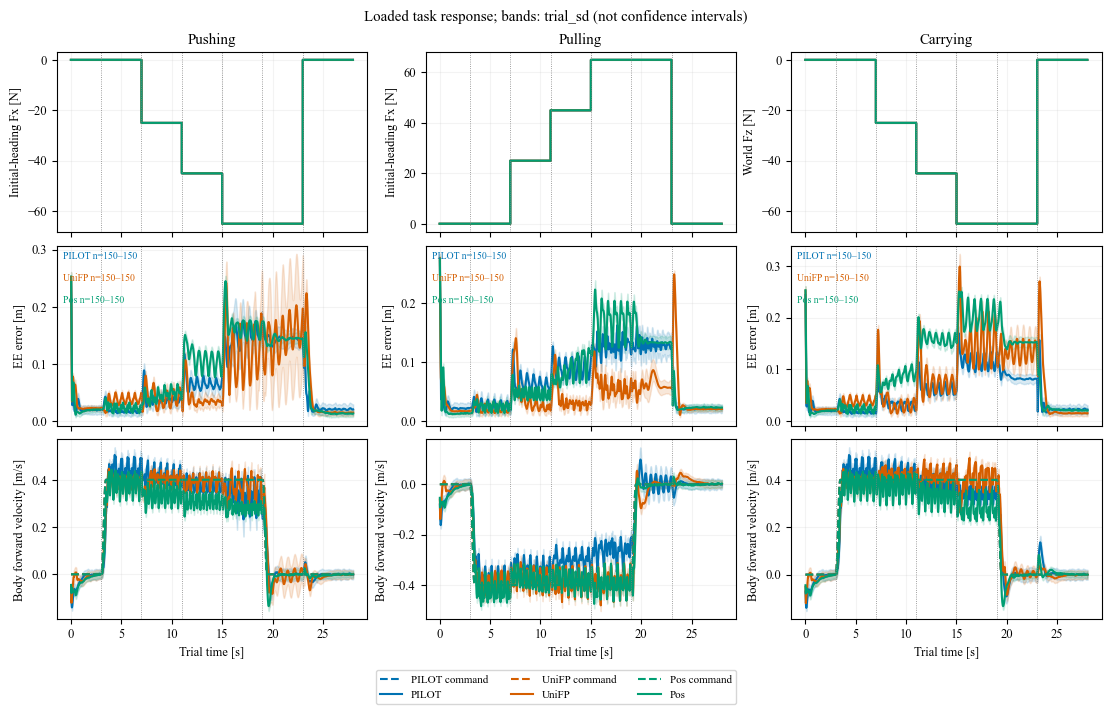

In [3]:
tables, figure, diagnostics = analysis.compare(CONFIG)
display(tables["main"])


## Focused physical limits and disturbance response
Percentages are converted once for display; CSV statistics retain their explicit units. Recovery times exclude unrecovered events. Complete windows alone contribute comparable peaks. CSV/LaTeX exports preserve unavailable results.


In [4]:
display(tables["physical_limits"])
display(tables["response"])


Saturation [%] ↓ Position [%] ↓ Velocity [%] ↓
Method Profile                                                
PILOT  pushing     0.000 ± 0.000  0.006 ± 0.002  0.000 ± 0.000
       pulling     0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
       carrying    0.000 ± 0.000  1.598 ± 0.008  0.000 ± 0.000
UniFP  pushing     0.019 ± 0.000  0.126 ± 0.009  0.000 ± 0.000
       pulling     0.002 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
       carrying    0.020 ± 0.000  0.066 ± 0.008  0.000 ± 0.000
Pos    pushing     0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
       pulling     0.000 ± 0.000  0.000 ± 0.000  0.000 ± 0.000
       carrying    0.000 ± 0.000  0.024 ± 0.002  0.000 ± 0.000

Peak EE [m] ↓ Recovery [s] ↓ Recovered [%] ↑  \
Method Profile                                                  
PILOT  pushing   0.140 ± 0.001  0.333 ± 0.024  78.167 ± 1.041   
       pulling   0.136 ± 0.000  0.330 ± 0.018  60.000 ± 1.323   
       carrying  0.132 ± 0.000  0.223 ± 0.012  75.000 ± 0.000   
UniFP  pushing   0.176 ± 0.002  0.437 ± 0.008  74.667 ± 0.289   
       pulling   0.156 ± 0.001  0.580 ± 0.016  99.833 ± 0.289   
       carrying  0.235 ± 0.001  0.622 ± 0.006  70.500 ± 1.732   
Pos    pushing   0.154 ± 0.001  0.253 ± 0.006  50.167 ± 0.289   
       pulling   0.136 ± 0.001  0.064 ± 0.004  74.667 ± 0.289   
       carrying  0.180 ± 0.000  0.192 ± 0.013  50.000 ± 0.000   

                EE recovered [%] ↑ Velocity recovered [%] ↑  
Method Profile                                               
PILOT  pushing      78.833 ± 0.764           88.167 ± 1.258  
       pulling      63.000 ± 1.732           84.667 ± 2.082  
       carrying     75.000 ± 0.000          100.000 ± 0.000  
UniFP  pushing      75.000 ± 0.000           98.000 ± 1.323  
       pulling     100.000 ± 0.000          100.000 ± 0.000  
       carrying     70.500 ± 1.732          100.000 ± 0.000  
Pos    pushing      50.167 ± 0.289          100.000 ± 0.000  
       pulling      75.000 ± 0.000           99.833 ± 0.289  
       carrying     50.000 ± 0.000          100.000 ± 0.000

## Task response
Actual applied load is plotted at interval start; EE error and body-forward command/measured velocity use successor timestamps. Dotted lines mark motion onset, load changes, stopping and release from metadata. No interpolation or zero-padding after failure. Survivor-count ranges appear on the figure; exact per-time counts are exported to task_response.csv.


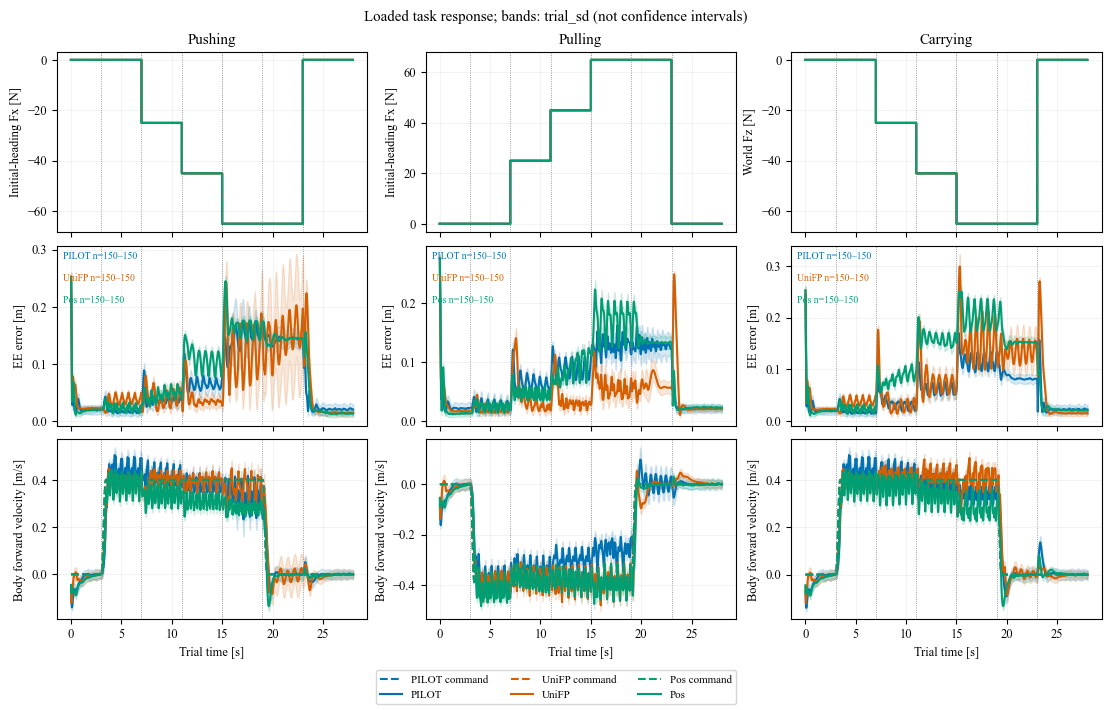

PILOT/pushing: surviving EE trials 150..150 (counts exported)
UniFP/pushing: surviving EE trials 150..150 (counts exported)
Pos/pushing: surviving EE trials 150..150 (counts exported)
PILOT/pulling: surviving EE trials 150..150 (counts exported)
UniFP/pulling: surviving EE trials 150..150 (counts exported)
Pos/pulling: surviving EE trials 150..150 (counts exported)
PILOT/carrying: surviving EE trials 150..150 (counts exported)
UniFP/carrying: surviving EE trials 150..150 (counts exported)
Pos/carrying: surviving EE trials 150..150 (counts exported)
CSV/LaTeX tables and PDF/PNG figure: /home/oyoungquist/Research/Genesis_Development/HCR_Genesis_PACT_Development/analysis/exp2_comparison


In [5]:
display(figure)
print("\n".join(diagnostics) or "No missing-data diagnostics.")
print("CSV/LaTeX tables and PDF/PNG figure:", CONFIG["output_dir"])
